In [2]:
# Import library
import os
import pandas as pd
import numpy as np

from sklearn.datasets import load_breast_cancer

# Membuat folder results untuk menyimpan hasil visualisasi
os.makedirs("results", exist_ok=True)

# Memuat dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

# Melihat ukuran dataset
print("Jumlah data:", X.shape)
print("Jumlah fitur:", X.shape[1])
print("Jumlah kelas:", y.nunique())

Jumlah data: (569, 30)
Jumlah fitur: 30
Jumlah kelas: 2


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Data Training:", X_train.shape)
print("Data Testing:", X_test.shape)

Data Training: (398, 30)
Data Testing: (171, 30)


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Membuat model Logistic Regression
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

# Melatih model
lr_model.fit(X_train, y_train)

# Melakukan prediksi
y_pred_lr = lr_model.predict(X_test)

print("Logistic Regression berhasil dijalankan!")

Logistic Regression berhasil dijalankan!


In [5]:
from sklearn.ensemble import RandomForestClassifier

# Membuat model Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Melatih model
rf_model.fit(X_train, y_train)

# Melakukan prediksi
y_pred_rf = rf_model.predict(X_test)

print("Random Forest berhasil dijalankan!")

Random Forest berhasil dijalankan!


In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Evaluasi Logistic Regression
hasil_lr = {
    "Algoritma": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred_lr),
    "Precision": precision_score(y_test, y_pred_lr, average="weighted"),
    "Recall": recall_score(y_test, y_pred_lr, average="weighted"),
    "F1-score": f1_score(y_test, y_pred_lr, average="weighted")
}

# Evaluasi Random Forest
hasil_rf = {
    "Algoritma": "Random Forest",
    "Accuracy": accuracy_score(y_test, y_pred_rf),
    "Precision": precision_score(y_test, y_pred_rf, average="weighted"),
    "Recall": recall_score(y_test, y_pred_rf, average="weighted"),
    "F1-score": f1_score(y_test, y_pred_rf, average="weighted")
}

# Membandingkan hasil
hasil = pd.DataFrame([hasil_lr, hasil_rf])

print(hasil.to_string(index=False))

          Algoritma  Accuracy  Precision   Recall  F1-score
Logistic Regression  0.988304   0.988304 0.988304  0.988304
      Random Forest  0.935673   0.935533 0.935673  0.935569


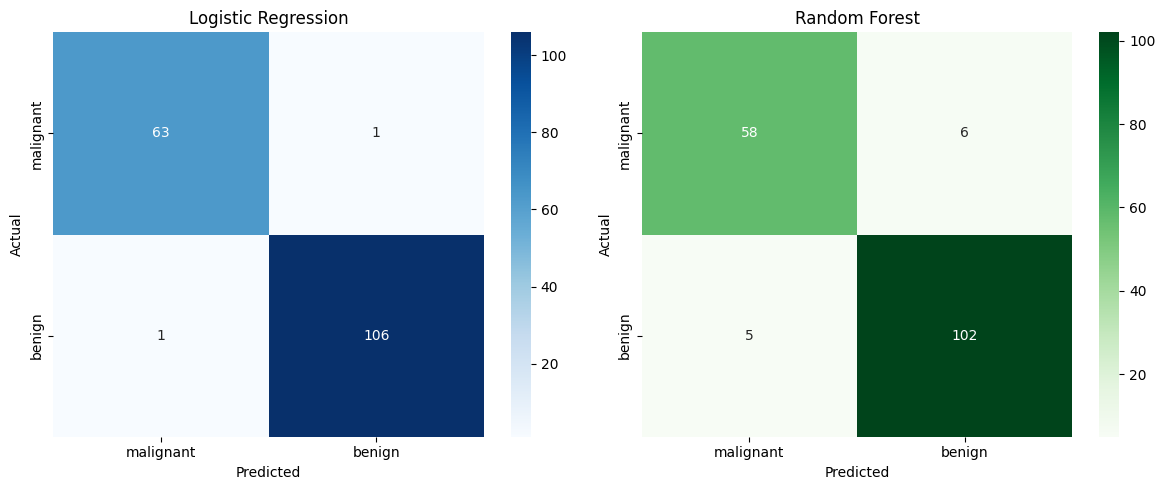

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Membuat confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Menampilkan kedua confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0],
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1],
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

axes[1].set_title("Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=300)
plt.show()

In [8]:
from sklearn.metrics import classification_report

print("LOGISTIC REGRESSION")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=data.target_names
))

print("RANDOM FOREST")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=data.target_names
))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171

RANDOM FOREST
              precision    recall  f1-score   support

   malignant       0.92      0.91      0.91        64
      benign       0.94      0.95      0.95       107

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171



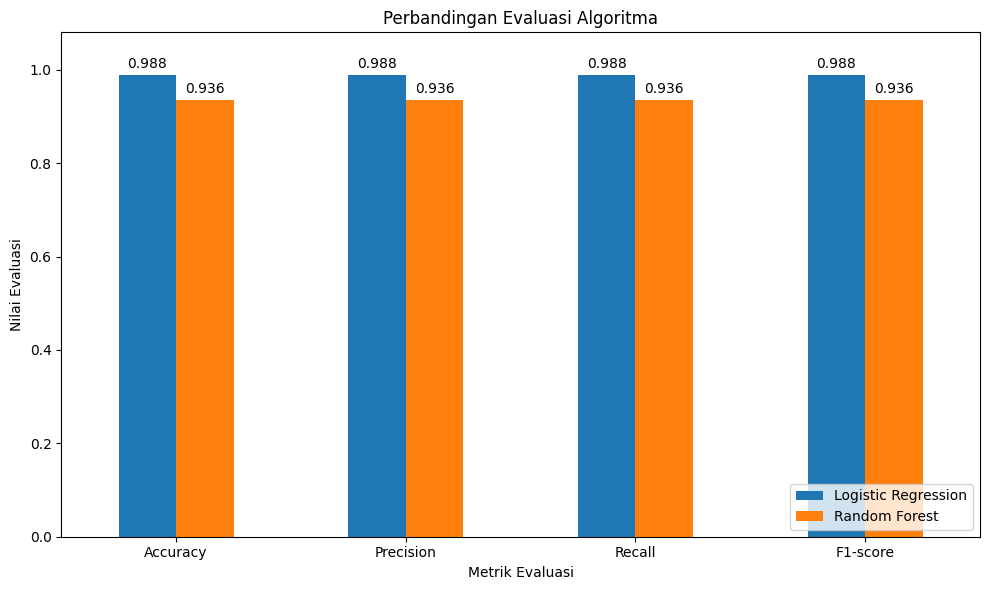

In [9]:
# Mengubah tabel menjadi format grafik (perbandingan langsung per metrik)
hasil_plot = hasil.set_index("Algoritma").T

ax = hasil_plot.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1.08),
    rot=0
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.title("Perbandingan Evaluasi Algoritma")
plt.ylabel("Nilai Evaluasi")
plt.xlabel("Metrik Evaluasi")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("results/evaluation_results.png", dpi=300)
plt.show()

In [10]:
import os

os.makedirs("results", exist_ok=True)

Analisis Hasil Eksperimen

Berdasarkan hasil pengujian, Logistic Regression dan Random Forest memiliki hasil klasifikasi yang berbeda. Perbedaan tersebut dapat dilihat dari nilai accuracy, precision, recall, dan F1-score yang diperoleh masing-masing algoritma. Algoritma dengan nilai evaluasi yang lebih tinggi menunjukkan hasil yang lebih baik pada metrik tersebut. Oleh karena itu, perbandingan kedua algoritma perlu dilakukan dengan melihat seluruh nilai evaluasi, bukan hanya accuracy.

Mengapa Accuracy Tidak Cukup dalam Klasifikasi Kanker?

Accuracy saja tidak cukup untuk menilai hasil klasifikasi kanker karena hanya menunjukkan jumlah seluruh prediksi yang benar. Dalam kasus kanker, model harus mampu mengenali pasien yang benar-benar memiliki kanker. Jika pasien yang sebenarnya menderita kanker justru diprediksi sehat, hal ini bisa berbahaya karena pasien dapat terlambat mendapatkan pengobatan. Oleh karena itu, recall juga penting untuk melihat kemampuan model dalam mendeteksi kanker. Precision dan F1-score juga digunakan untuk melihat ketepatan hasil prediksi model.

Kesimpulan

Berdasarkan percobaan yang telah dilakukan, kedua algoritma yaitu Logistic Regression dan Random Forest dapat digunakan untuk mengklasifikasikan data kanker. Kedua algoritma memiliki hasil evaluasi yang berbeda berdasarkan accuracy, precision, recall, dan F1-score. Algoritma yang memberikan hasil lebih baik ditentukan berdasarkan perbandingan nilai evaluasi serta kemampuannya dalam mendeteksi kelas kanker. Dengan demikian, pemilihan algoritma tidak hanya didasarkan pada nilai accuracy, tetapi juga perlu memperhatikan recall agar kesalahan dalam mendeteksi pasien yang menderita kanker dapat dikurangi.